# BomaTrack: Logistic Regression Base Model
**ICS 3202 | Semester Project Deliverable 2 | Team 7**

| Member | Part covered in our group presentation |
|---|---|
| Austin Maina (192076) | Problem, dataset and cleaning |
| Andeche Atetwe (190159) | Payment-history inputs and four observations |
| Yassir Mohammed (190375) | Logistic regression and time-based validation |
| Emmanuel Onyango (191258) | Test results and connection to BomaTrack |

## 1. Problem and approach
BomaTrack's research question was whether mobile rent tracking with arrears
prediction improved the **accuracy and timeliness of rent records** for small
Nairobi landlords, compared with manual practice. In this notebook, we tested
only the **late-payment prediction component**.

We studied whether a newly issued bill would be settled **after its due date**.
We labelled late bills as **1** and on-time bills as **0**, making this a
**supervised binary classification** task. Our base algorithm was
**logistic regression**.

We used public accounts-receivable data as a stand-in for payment histories.
These were **business invoices, not the stakeholder's rent records**. This
experiment tested the model workflow; it did not measure rental prediction
accuracy or improvement in landlords' records.

## 2. Data exploration and cleaning
We read the CSV, inspected the records and checked missing values, duplicate
rows, repeated invoice numbers, date order and the supplied late-day values.
The checks found **no missing cells, duplicates or inconsistent dates**.
We converted the three relevant date columns and calculated the target from
the due and settlement dates. All **2,466 invoices** were retained.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

raw = pd.read_csv('WA_Fn-UseC_-Accounts-Receivable.csv',
                  dtype={'customerID': str, 'invoiceNumber': str})
print('Data shape:', raw.shape, '| Customers:', raw['customerID'].nunique())
display(raw[['customerID', 'InvoiceDate', 'DueDate', 'SettledDate', 'DaysLate']].head(3))

df = raw.drop_duplicates().copy()
for column in ['InvoiceDate', 'DueDate', 'SettledDate']:
    df[column] = pd.to_datetime(df[column], format='%m/%d/%Y')

calculated_days_late = (df['SettledDate'] - df['DueDate']).dt.days.clip(lower=0)
print('Missing cells:', raw.isna().sum().sum())
print('Exact duplicates:', raw.duplicated().sum())
print('Repeated invoice numbers:', df['invoiceNumber'].duplicated().sum())
print('Invalid date order:', ((df['DueDate'] < df['InvoiceDate']) |
                              (df['SettledDate'] < df['InvoiceDate'])).sum())
print('DaysLate differences:', (calculated_days_late != df['DaysLate']).sum())
print('Non-positive invoice amounts:', (df['InvoiceAmount'] <= 0).sum())

df['Late'] = (df['SettledDate'] > df['DueDate']).astype(int)
df = df.sort_values(['InvoiceDate', 'customerID', 'invoiceNumber']).reset_index(drop=True)
print('Final rows:', len(df))

Data shape: (2466, 12) | Customers: 100


,customerID,InvoiceDate,DueDate,SettledDate,DaysLate
0,0379-NEVHP,1/2/2013,2/1/2013,1/15/2013,0
1,8976-AMJEO,1/26/2013,2/25/2013,3/3/2013,6
2,2820-XGXSB,7/3/2013,8/2/2013,7/8/2013,0


Missing cells: 0
Exact duplicates: 0
Repeated invoice numbers: 0
Invalid date order: 0
DaysLate differences: 0
Non-positive invoice amounts: 0
Final rows: 2466


## 3. Inputs taken from earlier payments
We created three inputs for each invoice using **only the same customer's
bills that had been issued and fully settled before the new invoice date**.
This kept future payment information out of the prediction.

| Input | Meaning |
|---|---|
| `prior_paid_count` | Number of earlier completed bills |
| `prior_late_rate` | Fraction of those bills paid late |
| `prior_mean_days_late` | Average overdue days across those bills (including zeros) |

We used zeros when no earlier paid bills existed. Customer ID was used only
to find payment history; it was not a model input. The current invoice's
settlement date and late-day value were not passed to the model.

In [2]:
df['prior_paid_count'] = 0
df['prior_late_rate'] = 0.0
df['prior_mean_days_late'] = 0.0

for customer_id, bills in df.groupby('customerID'):
    for index, bill in bills.iterrows():
        previous = bills[(bills['InvoiceDate'] < bill['InvoiceDate']) &
                         (bills['SettledDate'] < bill['InvoiceDate'])]
        if len(previous) > 0:
            df.loc[index, 'prior_paid_count'] = len(previous)
            df.loc[index, 'prior_late_rate'] = previous['Late'].mean()
            df.loc[index, 'prior_mean_days_late'] = previous['DaysLate'].mean()

FEATURES = ['prior_paid_count', 'prior_late_rate', 'prior_mean_days_late']
display(df.loc[df['prior_paid_count'] > 0, FEATURES + ['Late']].head(5).round(2))

,prior_paid_count,prior_late_rate,prior_mean_days_late,Late
105,2,0.0,0.0,0
109,1,0.0,0.0,0
110,1,0.0,0.0,0
113,1,0.0,0.0,0
114,1,0.0,0.0,0


## 4. Four EDA observations
We reserved **2013 invoices for the final test**. For our exploration and
model development we used invoices issued **and settled before 1 January
2013**, so their outcomes were already known. Ninety-nine earlier invoices
were still unsettled at that date and were not used for training.

We examined (1) the share of late invoices, (2) how many days late bills were,
(3) late-payment rates by quarter, and (4) differences by previous payment
history. These were associations in this dataset, not proof of causes. The final quarter included only bills settled by the cutoff, so its lower late rate did not prove that payments improved.

Development: 1178 | Test: 1189 | Earlier bills still unsettled: 99
1. 37.6% of development bills were late.
2. Late bills: median 8 days; 90th percentile 20 days.
3. Late rates differed across quarters:


,Late %
InvoiceDate,
2012Q1,42.1
2012Q2,41.0
2012Q3,38.7
2012Q4,25.6


4. Late rates differed by previous payment history:


,Bills,Late rate
History,,
Earlier bills all on time,367,0.117
Earlier bills include late,617,0.494
No earlier paid bills,194,0.490


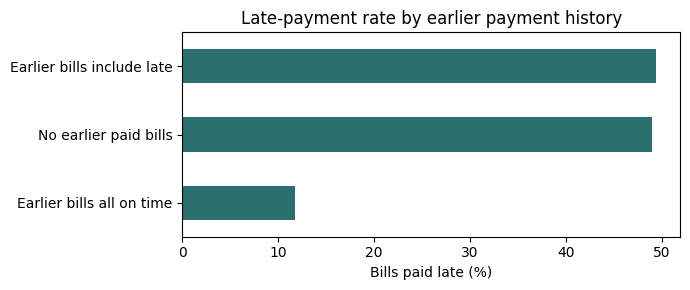

In [3]:
cutoff = pd.Timestamp('2013-01-01')
development = df[(df['InvoiceDate'] < cutoff) & (df['SettledDate'] < cutoff)].copy()
test = df[df['InvoiceDate'] >= cutoff].copy()
pending = ((df['InvoiceDate'] < cutoff) & (df['SettledDate'] >= cutoff)).sum()
print('Development:', len(development), '| Test:', len(test),
      '| Earlier bills still unsettled:', pending)

late_rate = development['Late'].mean()
late_days = development.loc[development['Late'] == 1, 'DaysLate']
quarterly = development.groupby(development['InvoiceDate'].dt.to_period('Q'))['Late'].mean()

development['History'] = 'No earlier paid bills'
development.loc[(development['prior_paid_count'] > 0) &
                (development['prior_late_rate'] == 0), 'History'] = 'Earlier bills all on time'
development.loc[development['prior_late_rate'] > 0, 'History'] = 'Earlier bills include late'
history_rates = development.groupby('History')['Late'].agg(['size', 'mean'])

print(f'1. {late_rate:.1%} of development bills were late.')
print(f'2. Late bills: median {late_days.median():.0f} days; '
      f'90th percentile {late_days.quantile(.9):.0f} days.')
print('3. Late rates differed across quarters:')
display((quarterly * 100).round(1).rename('Late %').to_frame())
print('4. Late rates differed by previous payment history:')
display(history_rates.rename(columns={'size': 'Bills', 'mean': 'Late rate'}).round(3))

(history_rates['mean'] * 100).sort_values().plot.barh(figsize=(7, 3), color='#2b6f70')
plt.xlabel('Bills paid late (%)')
plt.ylabel('')
plt.title('Late-payment rate by earlier payment history')
plt.tight_layout()
plt.show()

## 5. Base model and validation
We trained logistic regression on the three history inputs. We scaled the
inputs inside the model pipeline so the scaler learned from training rows
only. Logistic regression used its default **L2 regularisation**.

We checked the approach using three **time-based validation periods** in
2012. Each time, we trained on earlier bills already settled and predicted
bills in a later two-month period. We also compared the accuracy against
simply predicting that every bill would be on time.

The final time split included the same customer accounts in training and
test. It tested **later bills for existing accounts**, not performance on
entirely new customers. Each bill's inputs used only payments completed
before that bill was issued.

In [4]:
folds = [
    ('Apr-May 2012', '2012-04-01', '2012-06-01'),
    ('Jun-Jul 2012', '2012-06-01', '2012-08-01'),
    ('Aug-Sep 2012', '2012-08-01', '2012-10-01')
]
fold_results = []
for period, start, end in folds:
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    train_fold = development[(development['InvoiceDate'] < start) &
                             (development['SettledDate'] < start)]
    valid_fold = development[(development['InvoiceDate'] >= start) &
                             (development['InvoiceDate'] < end)]
    fold_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    fold_model.fit(train_fold[FEATURES], train_fold['Late'])
    prediction = fold_model.predict(valid_fold[FEATURES])
    fold_results.append({
        'Period': period,
        'Training bills': len(train_fold),
        'Validation bills': len(valid_fold),
        'Baseline accuracy': (valid_fold['Late'] == 0).mean(),
        'Model accuracy': accuracy_score(valid_fold['Late'], prediction),
        'Precision': precision_score(valid_fold['Late'], prediction, zero_division=0),
        'Recall': recall_score(valid_fold['Late'], prediction, zero_division=0)
    })
display(pd.DataFrame(fold_results).set_index('Period').round(3))

,Training bills,Validation bills,Baseline accuracy,Model accuracy,Precision,Recall
Period,,,,,,
Apr-May 2012,197,209,0.593,0.641,1.000,0.118
Jun-Jul 2012,412,207,0.599,0.638,1.000,0.096
Aug-Sep 2012,623,224,0.612,0.674,0.938,0.172


## 6. Final test on later invoices
After validation, we fitted the same model on the completed pre-2013 bills
and tested it on invoices issued in 2013. We used the standard **0.50**
probability threshold and did not change it using the test results.

We reported accuracy, precision, recall, F1 and ROC-AUC. The confusion matrix
showed correct predictions, false alerts and missed late payments.

,Accuracy,Precision,Recall,F1,ROC-AUC
Always on time,0.682,0.000,0.000,0.000,0.500
Logistic regression,0.737,0.874,0.201,0.327,0.826


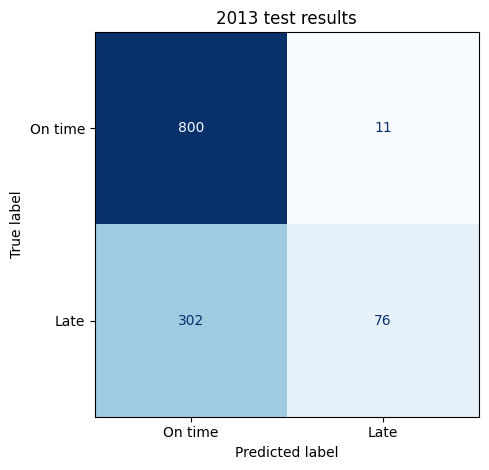

Correct late alerts: 76 | False alerts: 11 | Missed late bills: 302


In [5]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(development[FEATURES], development['Late'])

actual = test['Late']
probability = model.predict_proba(test[FEATURES])[:, 1]
predicted = (probability >= 0.50).astype(int)

results = pd.DataFrame({
    'Always on time': [(actual == 0).mean(), 0, 0, 0, 0.5],
    'Logistic regression': [accuracy_score(actual, predicted),
                            precision_score(actual, predicted),
                            recall_score(actual, predicted),
                            f1_score(actual, predicted),
                            roc_auc_score(actual, probability)]
}, index=['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']).T
display(results.round(3))

matrix = confusion_matrix(actual, predicted, labels=[0, 1])
ConfusionMatrixDisplay(matrix, display_labels=['On time', 'Late']).plot(
    cmap='Blues', colorbar=False)
plt.title('2013 test results')
plt.tight_layout()
plt.show()
tn, fp, fn, tp = matrix.ravel()
print(f'Correct late alerts: {tp} | False alerts: {fp} | Missed late bills: {fn}')

## 7. Example and model file
We tried one illustrative payment history: **six earlier bills, three paid
late, and an average overdue time of four days**. This was an example,
not an actual tenant record. We also saved the trained scaling values and
logistic regression weights in a small JSON file for the later app work.
The mobile app was **not connected** in this deliverable.

In [6]:
example = pd.DataFrame([[6, 0.5, 4]], columns=FEATURES)
example_probability = model.predict_proba(example)[0, 1]
print(f'Example late-payment score: {example_probability:.1%}')
print('Prediction:', 'Late' if example_probability >= 0.5 else 'On time')

scaler = model.named_steps['standardscaler']
classifier = model.named_steps['logisticregression']
model_data = {
    'model': 'logistic_regression',
    'features': FEATURES,
    'mean': scaler.mean_.tolist(),
    'scale': scaler.scale_.tolist(),
    'coefficients': classifier.coef_[0].tolist(),
    'intercept': float(classifier.intercept_[0]),
    'threshold': 0.5
}
with open('late_payment_model.json', 'w', encoding='utf-8') as file:
    json.dump(model_data, file, indent=2)
print('Saved late_payment_model.json')

Example late-payment score: 40.0%
Prediction: On time
Saved late_payment_model.json


## 8. What we concluded
The logistic regression model performed better than the always-on-time
baseline, but it **missed most late bills**. Its precision was much higher
than its recall. We treated it as a **base model**, not a validated rental
predictor. Its **73.7% accuracy described invoice predictions**, not the
accuracy of rent records or an improvement caused by BomaTrack.

We identified a **small decision tree** for later comparison using the
**same three inputs, time periods and metrics**. We had not run that model.
Testing on suitable rental payment data remained a separate validation step.

**Connection to the app:** we mapped a customer account to a tenant account,
an invoice to a rent charge, and settlement to that charge being fully paid.
This mapping connected the workflow, not the two populations' behaviour.
The proposed feature used payment history to prioritise reminders; it did
not reconcile M-Pesa transactions or predict how long a tenant would stay.

**Separate research evaluation:** our research plan proposed checking
landlords' rent records against M-Pesa statements before and after using
the app. That compared manual and app-assisted record accuracy and how
quickly arrears were noticed. We did **not** carry out that evaluation in
this notebook.

**Data source:** [Accounts receivable CSV mirror](https://github.com/pthiagu2/DataMining)